In [3]:
# **Model Training: Random Forest - Your Name (ID)**

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

In [4]:
# Load your PCA dataset
stroke_pca = pd.read_csv("stroke .csv")  # Your file

It seems the notebook could not find the `stroke.csv` file. I'll add a cell to download it from the provided link.

In [5]:
# Separate features (PCs) and target
X = stroke_pca.drop('Diagnosis Encoded', axis=1)  # PCs 1-16
y = stroke_pca['Diagnosis Encoded']  # 0 or 1

# Split into train (80%) and test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:
# Split into train (80%) and test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [7]:
# Create Random Forest model
rf_model = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42)  # 100 trees

In [8]:
# Train the model

rf_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=300,
                       random_state=42)

In [9]:
# Predict on test data
y_pred = rf_model.predict(X_test)

In [10]:
# Evaluate

# Convert y_pred to a pandas Series with the original index of y_test
y_pred = pd.Series(y_pred, index=X_test.index) # Use the index of the modified X_test

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))  # Shows precision, recall for stroke/no stroke
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))  # Shows true/false positives/negatives

Accuracy: 0.94

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.95      0.94      1253
           1       0.95      0.93      0.94      1247

    accuracy                           0.94      2500
   macro avg       0.94      0.94      0.94      2500
weighted avg       0.94      0.94      0.94      2500


Confusion Matrix:
[[1187   66]
 [  85 1162]]


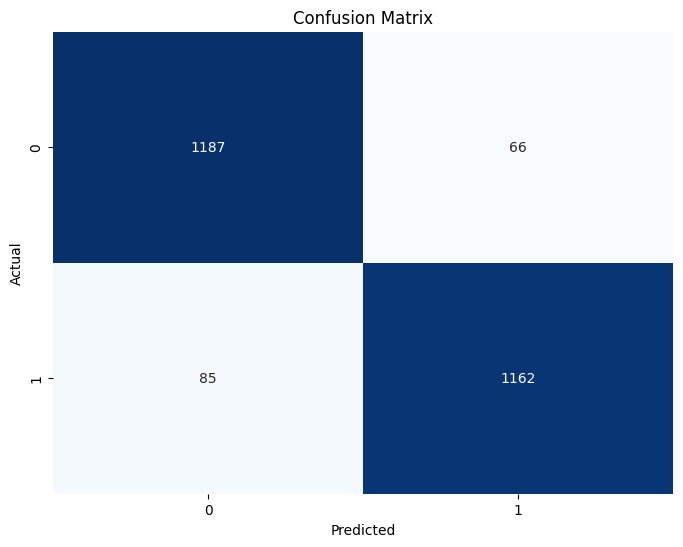

In [11]:
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

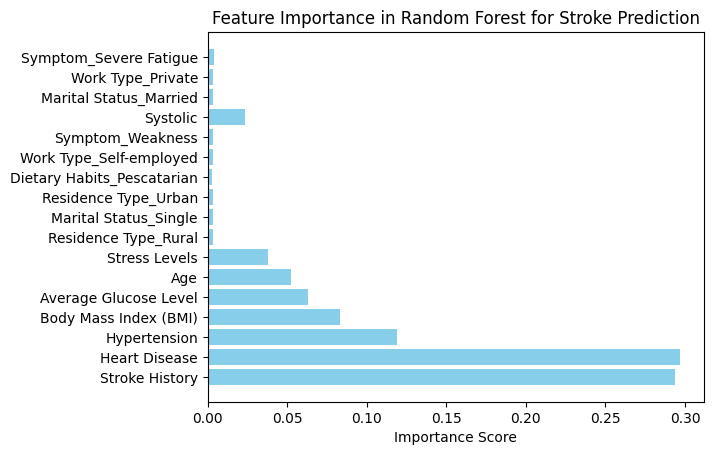

In [12]:
# Feature Importance Plot
importances = rf_model.feature_importances_
plt.barh(X_train.columns, importances, color='skyblue') # Use X_train.columns
plt.xlabel('Importance Score')
plt.title('Feature Importance in Random Forest for Stroke Prediction')
plt.show()